# 4.4 การเพิ่มขึ้นเกิดขึ้นได้อย่างไร — การรับเข้า การสูญเสีย และการเติบโต

จำนวนคงอยู่ที่เพิ่มขึ้นใน 4.1 เป็นผลรวมของการรับเข้า การออก และความต่างที่ยังกระทบยอดไม่ได้
หัวข้อนี้ใช้ **เหตุการณ์รับเข้าและสูญเสียที่บันทึกจริง** จากระบบ HROPS ของสำนักงานปลัดกระทรวงสาธารณสุข (สป.สธ.) ปีงบประมาณ 2560–2568
(ปีงบ 2569 ดึงข้อมูลเมื่อ 5 มี.ค. 2569 และจำนวนเกษียณเป็นค่าคาดการณ์ จึงไม่ใช้ในการเปรียบเทียบเต็มปี)

คำถาม
1. เอกลักษณ์ $W_{pt}-W_{p,t-1}=I_{pt}-O_{pt}+A_{pt}$ กระทบยอดได้แค่ไหน — $A$ คือส่วนที่เหลือ ไม่ใช่ "การจ้างที่ซ่อนอยู่"
2. อัตราการเติบโตที่ตรงช่วงเวลากับข้อมูลเหตุการณ์ และความเข้มของการรับเข้า/ออก ต่างกันอย่างไรระหว่างวิชาชีพและจังหวัด
3. ภาระงานปีก่อนสัมพันธ์กับการรับเข้า/ลาออกในปีถัดไปแค่ไหน (ความสัมพันธ์ ไม่ใช่ผลเชิงเหตุผล)

เหตุการณ์ ≠ บุคคลที่ไม่ซ้ำ และ ≠ ผู้สำเร็จการศึกษาใหม่ — คนเดียวอาจมีหลายเหตุการณ์ และการเปลี่ยนประเภทการจ้างอาจปรากฏเป็นการรับเข้า

In [1]:
import sys
from pathlib import Path
_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "analysis.toml").exists())
sys.path.insert(0, str(_root / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from chapter4 import config as C, panels as P, metrics as M, models as MD, reporting as R
from chapter4.ingest import load

pd.options.display.max_columns = 40
pd.options.display.width = 200
FONT = R.setup_style()
S = R.Section("4_4")
CAD = C.CADRES
EN = C.CADRE_EN
FY0, FY1 = C.CFG["years"]["flow_first_fy"], C.CFG["years"]["flow_last_complete_fy"]
BK = int(P.key().query("is_bangkok").prov_code.iloc[0])
KEY = P.key()[lambda d: ~d.is_bangkok].set_index("prov_code")
NAME = KEY.province.to_dict()
print(C.effective_config("4_4"))
T43 = C.OUTPUTS / "chapter4_3" / "tables"
if not (T43 / "T43_PRIORITY_RANKS.csv").exists():
    raise FileNotFoundError("missing 4.3 outputs - run: python -m chapter4.build --section 4.3")
PRI = pd.read_csv(T43 / "T43_PRIORITY_RANKS.csv", encoding="utf-8-sig")

{
 "years": {
  "long_first": 2013,
  "long_last": 2025,
  "casemix_first": 2018,
  "casemix_last": 2025,
  "morbidity_first": 2022,
  "morbidity_last": 2025,
  "flow_first_fy": 2017,
  "flow_last_complete_fy": 2025,
  "recent_window_years": 5,
  "pre_transfer_last": 2022,
  "covid_years": [
   2020,
   2021,
   2022
  ]
 },
 "geography": {
  "bangkok": "กรุงเทพมหานคร",
  "provincial_exclude": [
   "กรุงเทพมหานคร"
  ]
 },
 "flows": {
  "exposure_note": "Events per 100 prior-year MOPH-wide staff; the stock is broader than the OPS event universe.",
  "ppml_min_events": 1
 },
 "random_seed": 20260925
}


## 1. อ่านและตรวจสมุดงานต้นฉบับ
หัวตารางหลายชั้นถูกอ่านจาก merged cells ของแต่ละ sheet (ตำแหน่งคอลัมน์เปลี่ยนทุกปี) เก็บหมวดเหตุการณ์และประเภทการจ้างตามต้นฉบับ
ช่องว่างถูกเก็บเป็นธง `blank` แล้วตรวจว่าตีความเป็นศูนย์ได้หรือไม่จากผลรวมย่อยที่ตีพิมพ์

In [2]:
EV = load("flow_events")
PUB = load("flow_published")
META = load("flow_sheet_meta")
display(META[["workbook", "sheet", "note"]].drop_duplicates("workbook"))
S.table("T44_SHEET_METADATA", META, "ข้อมูลกำกับของแต่ละ sheet (ชื่อ หมายเหตุวันที่ดึงข้อมูล)")
print("sheets whose note gives the 5 March 2026 extraction date:", META.note.fillna("").str.contains("5 มีนาคม 2569").sum(), "of", len(META))
ev = EV.copy()
ev["events0"] = ev.events.fillna(0)

# (a) components -> published subtotal columns, row by row
e_comp = ev[ev.direction == "entry"].groupby(["fiscal_year", "row", "cadre", "category"]).events0.sum()
e_sub = (PUB[(PUB.workbook == "entry") & (PUB.column_kind == "category_total") & (PUB.row_type != "footer")]
         .assign(v=lambda d: d.events.fillna(0)).groupby(["fiscal_year", "row", "cadre", "category"]).v.sum())
chk_a = pd.concat([e_comp.rename("components"), e_sub.rename("published_subtotal")], axis=1).fillna(0)
chk_a["diff"] = chk_a.components - chk_a.published_subtotal
# (b) components -> cadre total column
e_cad = ev[ev.direction == "entry"].groupby(["fiscal_year", "row", "cadre"]).events0.sum()
e_cadpub = (PUB[(PUB.workbook == "entry") & (PUB.column_kind == "total") & (PUB.category == "cadre_total") & (PUB.row_type != "footer")]
            .assign(v=lambda d: d.events.fillna(0)).groupby(["fiscal_year", "row", "cadre"]).v.sum())
chk_b = pd.concat([e_cad.rename("components"), e_cadpub.rename("published_cadre_total")], axis=1).fillna(0)
chk_b["diff"] = chk_b.components - chk_b.published_cadre_total
# (c) province rows -> footer, per cadre total column and grand total
foot = PUB[(PUB.workbook == "entry") & (PUB.row_type == "footer")]
f_cad = foot[foot.category == "cadre_total"].groupby(["fiscal_year", "cadre"]).events.sum()
rows_cad = ev[ev.direction == "entry"].groupby(["fiscal_year", "cadre"]).events0.sum()
chk_c = pd.concat([rows_cad.rename("sum_of_rows"), f_cad.rename("published_footer")], axis=1)
chk_c["diff"] = chk_c.sum_of_rows - chk_c.published_footer
f_grand = foot[foot.category == "grand_total"].groupby("fiscal_year").events.sum()
g_rows = ev[ev.direction == "entry"].groupby("fiscal_year").events0.sum()
f_cadsum = foot[foot.category == "cadre_total"].groupby("fiscal_year").events.sum()
chk_g = pd.DataFrame({"sum_of_components": g_rows, "sum_of_cadre_footers": f_cadsum, "published_grand_footer": f_grand})
chk_g["grand_minus_components"] = chk_g.published_grand_footer - chk_g.sum_of_components
# row-level grand total column
r_grand = PUB[(PUB.workbook == "entry") & (PUB.category == "grand_total") & (PUB.row_type != "footer")].assign(v=lambda d: d.events.fillna(0)).groupby(["fiscal_year", "row"]).v.sum()
r_comp = ev[ev.direction == "entry"].groupby(["fiscal_year", "row"]).events0.sum()
chk_r = pd.concat([r_comp.rename("components"), r_grand.rename("row_grand_total")], axis=1).fillna(0)
chk_r["diff"] = chk_r.components - chk_r.row_grand_total
ENTRY_AUDIT = pd.DataFrame([
    dict(check="components = category subtotal (every row, cadre, category)", cells=len(chk_a), mismatches=int((chk_a["diff"] != 0).sum()), max_abs_diff=chk_a["diff"].abs().max()),
    dict(check="components = cadre total column (every row)", cells=len(chk_b), mismatches=int((chk_b["diff"] != 0).sum()), max_abs_diff=chk_b["diff"].abs().max()),
    dict(check="sum of rows = cadre footer", cells=len(chk_c), mismatches=int((chk_c["diff"].fillna(0) != 0).sum()), max_abs_diff=chk_c["diff"].abs().max()),
    dict(check="row components = row grand-total column", cells=len(chk_r), mismatches=int((chk_r["diff"] != 0).sum()), max_abs_diff=chk_r["diff"].abs().max()),
    dict(check="grand footer = all components", cells=len(chk_g), mismatches=int((chk_g.grand_minus_components != 0).sum()), max_abs_diff=chk_g.grand_minus_components.abs().max())])
S.table("T44_ENTRY_WORKBOOK_AUDIT", ENTRY_AUDIT, "ตรวจสมุดงานรับเข้า: ผลรวมองค์ประกอบเทียบผลรวมย่อยและยอดรวมที่ตีพิมพ์", main=True)
display(ENTRY_AUDIT)
S.table("T44_ENTRY_FOOTER_CHECK", chk_c.reset_index(), "ผลรวมรายจังหวัด เทียบยอดรวมท้ายตาราง แยกวิชาชีพ (รับเข้า)")
S.table("T44_ENTRY_GRAND_CHECK", chk_g.reset_index(), "ยอดรวมทั้งหมดท้ายตาราง เทียบผลรวมองค์ประกอบ (รับเข้า)")
display(chk_c[chk_c["diff"].fillna(0) != 0])
display(chk_g)
S.table("T44_ENTRY_MISMATCHES", pd.concat([chk_a[chk_a["diff"] != 0].reset_index().assign(check="category"),
                                           chk_b[chk_b["diff"] != 0].reset_index().assign(check="cadre"),
                                           chk_r[chk_r["diff"] != 0].reset_index().assign(check="row_grand")]),
        "เซลล์ที่องค์ประกอบไม่เท่าผลรวมที่ตีพิมพ์ (รับเข้า)")

# exits: components vs each fiscal-year total column, vs the all-years column, vs footers, vs the summary sheet
x = ev[ev.direction == "exit"]
x_comp = x.groupby(["fiscal_year", "row", "cadre"]).events0.sum()
x_tot = (PUB[(PUB.workbook == "exit") & (PUB.column_kind == "total") & (PUB.category == "total") & (PUB.row_type != "footer")]
         .assign(v=lambda d: d.events.fillna(0)).groupby(["fiscal_year", "row", "cadre"]).v.sum())
chk_x = pd.concat([x_comp.rename("components"), x_tot.rename("published_total")], axis=1).fillna(0)
chk_x["diff"] = chk_x.components - chk_x.published_total
xf = PUB[(PUB.workbook == "exit") & (PUB.row_type == "footer") & (PUB.category == "total")].groupby(["fiscal_year", "cadre"]).events.sum()
chk_xf = pd.concat([x.groupby(["fiscal_year", "cadre"]).events0.sum().rename("sum_of_rows"), xf.rename("published_footer")], axis=1)
chk_xf["diff"] = chk_xf.sum_of_rows - chk_xf.published_footer
summ = PUB[(PUB.workbook == "exit") & (PUB.row_type == "summary_region")].copy()
summ["events"] = pd.to_numeric(summ.events, errors="coerce").fillna(0)
reg_map = pd.concat([KEY.health_region, pd.Series({np.nan: 0})])
x_reg = x.assign(region=x.health_region.fillna(-1)).copy()
x_reg["region_label"] = np.where(x_reg.row_type == "central_office", "สำนักงานปลัดฯ (ส่วนกลาง)", x_reg.health_region.astype("Int64").astype(str))
agg_reg = x_reg.groupby(["region_label", "cadre", "category"]).events0.sum()
summ["region_label"] = summ.row_label.astype(str).str.replace(".0", "", regex=False)
summ = summ[summ.region_label != "ผลรวมทั้งหมด"]           # the summary sheet's own total row is not a region
s_reg = summ[summ.category.isin(list(set(x.category)))].groupby(["region_label", "cadre", "category"]).events.sum()
chk_s = pd.concat([agg_reg.rename("province_sheets"), s_reg.rename("summary_sheet")], axis=1).fillna(0)
chk_s["diff"] = chk_s.province_sheets - chk_s.summary_sheet
EXIT_AUDIT = pd.DataFrame([
    dict(check="components = fiscal-year total column (every row)", cells=len(chk_x), mismatches=int((chk_x["diff"] != 0).sum()), max_abs_diff=chk_x["diff"].abs().max()),
    dict(check="sum of rows = footer (fiscal year x cadre)", cells=len(chk_xf), mismatches=int((chk_xf["diff"].fillna(0) != 0).sum()), max_abs_diff=chk_xf["diff"].abs().max()),
    dict(check="cadre sheets pooled FY2017-2026 = summary sheet (region x cadre x reason)", cells=len(chk_s), mismatches=int((chk_s["diff"] != 0).sum()), max_abs_diff=chk_s["diff"].abs().max())])
S.table("T44_EXIT_WORKBOOK_AUDIT", EXIT_AUDIT, "ตรวจสมุดงานสูญเสีย", main=True)
display(EXIT_AUDIT)
S.table("T44_EXIT_FOOTER_CHECK", chk_xf.reset_index(), "ผลรวมรายจังหวัด เทียบยอดรวมท้ายตาราง (สูญเสีย)")
S.table("T44_EXIT_SUMMARY_CHECK", chk_s[chk_s["diff"] != 0].reset_index(), "ส่วนต่างระหว่าง sheet รายวิชาชีพกับ sheet สรุป")

# independent copy: condensed layout
cond = load("flow_entry_condensed")
cc = cond[cond.category != "total"].groupby(["fiscal_year", "row_label", "cadre", "category"]).events.sum(min_count=1).fillna(0)
ours = ev[ev.direction == "entry"].groupby(["fiscal_year", "row_label", "cadre", "category"]).events0.sum()
chk_cond = pd.concat([ours.rename("full_layout"), cc.rename("condensed_layout")], axis=1).fillna(0)
chk_cond["diff"] = chk_cond.full_layout - chk_cond.condensed_layout
S.table("T44_CONDENSED_COPY_CHECK", chk_cond[chk_cond["diff"] != 0].reset_index(), "ส่วนต่างระหว่างสมุดงานรับเข้าสองรูปแบบ (ต้องว่าง)")
S.claim("c44_condensed_mismatch_cells", int((chk_cond["diff"] != 0).sum()), "int", "เซลล์")
S.claim("c44_condensed_cells", len(chk_cond), "int", "เซลล์")

# blanks
bl = ev.groupby(["direction", "cadre"]).agg(cells=("blank", "size"), blank=("blank", "sum")).reset_index()
S.table("T44_BLANK_CELLS", bl, "จำนวนช่องว่างในสมุดงาน (ตีความเป็น 'ไม่มีเหตุการณ์' เมื่อผลรวมย่อยของแถวลงตัว)")
for r in ENTRY_AUDIT.itertuples():
    S.claim(f"c44_entry_audit_{r.Index}", r.mismatches, "int", "เซลล์")
for r in EXIT_AUDIT.itertuples():
    S.claim(f"c44_exit_audit_{r.Index}", r.mismatches, "int", "เซลล์")

,workbook,sheet,note
0,entry,ปีงบ 60,หมายเหตุ : ข้อมูลนี้มาจากการบันทึกข้อมูลในระบบ...
10,exit,1.นายแพทย์,หมายเหตุ : ดึงข้อมูลสูญเสียจากระบบสารสนเทศเพื่...


sheets whose note gives the 5 March 2026 extraction date: 17 of 17


,check,cells,mismatches,max_abs_diff
0,"components = category subtotal (every row, cad...",14014,0,0.0
1,components = cadre total column (every row),5390,0,0.0
2,sum of rows = cadre footer,70,1,1.0
3,row components = row grand-total column,770,76,598.0
4,grand footer = all components,10,2,9895.0


,,sum_of_rows,published_footer,diff
fiscal_year,cadre,,,
2020,ทันตแพทย์,572.0,571.0,1.0


,sum_of_components,sum_of_cadre_footers,published_grand_footer,grand_minus_components
fiscal_year,,,,
2017,20431.0,20431.0,20431.0,0.0
2018,25349.0,25349.0,25349.0,0.0
2019,20064.0,20064.0,20064.0,0.0
2020,39563.0,39562.0,39562.0,-1.0
2021,19253.0,19253.0,19253.0,0.0
2022,19596.0,19596.0,9701.0,-9895.0
2023,19670.0,19670.0,19670.0,0.0
2024,18536.0,18536.0,18536.0,0.0
2025,19170.0,19170.0,19170.0,0.0


,check,cells,mismatches,max_abs_diff
0,components = fiscal-year total column (every row),5400,0,0.0
1,sum of rows = footer (fiscal year x cadre),70,0,0.0
2,cadre sheets pooled FY2017-2026 = summary shee...,455,4,1.0


### ข้อบกพร่องของยอดรวมที่ตีพิมพ์ และการตัดสินใจเชิงวิเคราะห์
ใช้ผลรวมขององค์ประกอบที่ตรวจสอบแล้วแทนยอดรวมท้ายตารางที่ไม่ลงตัว (ต้นฉบับไม่ถูกแก้ไข)

In [3]:
dec = []
for (fy, c), r in chk_c[chk_c["diff"].fillna(0) != 0].iterrows():
    dec.append(dict(workbook="entry", fiscal_year=fy, cadre=c, sum_of_rows=r.sum_of_rows, published=r.published_footer, difference=r["diff"],
                    decision="ใช้ผลรวมรายจังหวัด (องค์ประกอบลงตัวกับผลรวมย่อยของทุกแถว)"))
for fy, r in chk_g[chk_g.grand_minus_components != 0].iterrows():
    dec.append(dict(workbook="entry", fiscal_year=fy, cadre="ALL (grand footer)", sum_of_rows=r.sum_of_components, published=r.published_grand_footer,
                    difference=-r.grand_minus_components, decision="ใช้ผลรวมองค์ประกอบ; ยอดรวมท้ายตารางไม่เท่ากับผลรวมของยอดรายวิชาชีพ"))
rg = chk_r[chk_r["diff"] != 0].reset_index()
for fy, g_ in rg.groupby("fiscal_year"):
    nurse_fy = ev[(ev.direction == "entry") & (ev.fiscal_year == fy) & (ev.cadre == "พยาบาลวิชาชีพ")].groupby("row").events0.sum()
    omits_nursing = bool(np.allclose(g_.set_index("row")["diff"], nurse_fy.reindex(g_.row).values))
    dec.append(dict(workbook="entry", fiscal_year=fy, cadre=f"row grand-total column ({len(g_)} rows)", sum_of_rows=g_.components.sum(),
                    published=g_.row_grand_total.sum(), difference=g_["diff"].sum(),
                    decision="คอลัมน์รวมทั้งหมดรายแถวไม่รวมพยาบาลวิชาชีพทุกแถว" if omits_nursing else "คอลัมน์รวมรายแถวไม่ลงตัว; ใช้ผลรวมองค์ประกอบ"))
for r in chk_s[chk_s["diff"] != 0].reset_index().itertuples():
    dec.append(dict(workbook="exit (summary sheet)", fiscal_year="2017-2026 pooled", cadre=f"{r.cadre} | {r.category} | region {r.region_label}",
                    sum_of_rows=r.province_sheets, published=r.summary_sheet, difference=r.diff, decision="ใช้ sheet รายวิชาชีพรายจังหวัด; sheet สรุปใช้ตรวจเท่านั้น"))
for (fy, c), r in chk_xf[chk_xf["diff"].fillna(0) != 0].iterrows():
    dec.append(dict(workbook="exit", fiscal_year=fy, cadre=c, sum_of_rows=r.sum_of_rows, published=r.published_footer, difference=r["diff"],
                    decision="ใช้ผลรวมรายจังหวัด"))
DEC = pd.DataFrame(dec, columns=["workbook", "fiscal_year", "cadre", "sum_of_rows", "published", "difference", "decision"])
S.table("T44_PARSING_DECISIONS", DEC, "ยอดรวมที่ตีพิมพ์ไม่ลงตัว และการตัดสินใจที่ใช้", main=True)
display(DEC)
S.claim("c44_published_total_defects", len(DEC), "int", "รายการ")
for r in DEC.itertuples():
    S.claim(f"c44_defect_{r.workbook}_{r.fiscal_year}_{r.cadre}", r.difference, "{:+.0f}", "เหตุการณ์")

,workbook,fiscal_year,cadre,sum_of_rows,published,difference,decision
0,entry,2020,ทันตแพทย์,572.0,571.0,1.0,ใช้ผลรวมรายจังหวัด (องค์ประกอบลงตัวกับผลรวมย่อ...
1,entry,2020,ALL (grand footer),39563.0,39562.0,1.0,ใช้ผลรวมองค์ประกอบ; ยอดรวมท้ายตารางไม่เท่ากับผ...
2,entry,2022,ALL (grand footer),19596.0,9701.0,9895.0,ใช้ผลรวมองค์ประกอบ; ยอดรวมท้ายตารางไม่เท่ากับผ...
3,entry,2022,row grand-total column (76 rows),19568.0,9673.0,9895.0,คอลัมน์รวมทั้งหมดรายแถวไม่รวมพยาบาลวิชาชีพทุกแถว
4,exit (summary sheet),2017-2026 pooled,พยาบาลวิชาชีพ | resignation | region 3,2864.0,2865.0,-1.0,ใช้ sheet รายวิชาชีพรายจังหวัด; sheet สรุปใช้ต...
5,exit (summary sheet),2017-2026 pooled,นักวิชาการสาธารณสุข | retirement | region 4,508.0,509.0,-1.0,ใช้ sheet รายวิชาชีพรายจังหวัด; sheet สรุปใช้ต...
6,exit (summary sheet),2017-2026 pooled,นักวิชาการสาธารณสุข | retirement | region สำนั...,38.0,37.0,1.0,ใช้ sheet รายวิชาชีพรายจังหวัด; sheet สรุปใช้ต...
7,exit (summary sheet),2017-2026 pooled,พยาบาลวิชาชีพ | resignation | region สำนักงานป...,12.0,11.0,1.0,ใช้ sheet รายวิชาชีพรายจังหวัด; sheet สรุปใช้ต...


## 2. ภาพรวมเหตุการณ์ (76 จังหวัด ไม่รวมส่วนกลาง) ปีงบ 2560–2568

In [4]:
ev76 = ev[(ev.row_type == "province") & ev.cadre.isin(CAD) & ev.fiscal_year.between(FY0, FY1)].copy()
ev76["prov_code"] = ev76.prov_code.astype(int)
central = ev[(ev.row_type == "central_office") & ev.cadre.isin(CAD)].groupby(["fiscal_year", "direction", "cadre"]).events0.sum().reset_index()
S.table("T44_CENTRAL_OFFICE_EVENTS", central, "เหตุการณ์ของส่วนกลาง (แสดงแยก ไม่รวมในการวิเคราะห์รายจังหวัด)")
EVL = ev76.groupby(["fiscal_year", "prov_code", "cadre", "direction", "category", "employment_type"], dropna=False).events0.sum().reset_index().rename(columns={"events0": "events"})
S.table("T44_EVENTS_LONG", EVL, "ตารางเหตุการณ์ long format: ปีงบ × จังหวัด × วิชาชีพ × ทิศทาง × หมวด × ประเภทการจ้าง")
nat = EVL.groupby(["fiscal_year", "cadre", "direction", "category"]).events.sum().unstack(["direction", "category"]).fillna(0)
S.table("T44_EVENTS_NATIONAL", nat.reset_index().set_axis(["fiscal_year", "cadre"] + [f"{a}__{b}" for a, b in nat.columns], axis=1),
        "เหตุการณ์รายปีงบ แยกวิชาชีพ ทิศทาง และหมวด (76 จังหวัด)", main=True)
emp = EVL[EVL.direction == "entry"].groupby(["fiscal_year", "cadre", "employment_type"]).events.sum().unstack().fillna(0)
S.table("T44_ENTRY_EMPLOYMENT_TYPE", emp.reset_index(), "การรับเข้าแยกประเภทการจ้าง (ขรก./พรก./พกส./ลจค.)")
display(emp.xs("พยาบาลวิชาชีพ", level="cadre"))
tot = EVL.groupby(["fiscal_year", "cadre", "direction"]).events.sum().unstack().fillna(0)
tot["net"] = tot.entry - tot.exit
for c in CAD:
    z = tot.xs(c, level="cadre")
    S.claim(f"c44_{EN[c]}_entries_total", z.entry.sum(), "int", "เหตุการณ์")
    S.claim(f"c44_{EN[c]}_exits_total", z.exit.sum(), "int", "เหตุการณ์")
    S.claim(f"c44_{EN[c]}_net_total", z.net.sum(), "int", "เหตุการณ์")
    S.claim(f"c44_{EN[c]}_exit_entry_ratio", z.exit.sum() / z.entry.sum(), "{:.2f}", "")
nx = EVL[EVL.direction == "exit"].groupby(["cadre", "category"]).events.sum().unstack()
nx_share = 100 * nx.div(nx.sum(axis=1), axis=0)
S.table("T44_EXIT_COMPOSITION", nx_share.reset_index(), "องค์ประกอบของการสูญเสียตามสาเหตุ (%, ปีงบ 2560–2568)", main=True)
display(nx_share.round(1))
for c in CAD:
    for cat in nx.columns:
        S.claim(f"c44_{EN[c]}_exit_share_{cat}", nx_share.loc[c, cat], "{:.1f}", "%")
ne = EVL[EVL.direction == "entry"].groupby(["cadre", "category"]).events.sum().unstack()
ne_share = 100 * ne.div(ne.sum(axis=1), axis=0)
S.table("T44_ENTRY_COMPOSITION", ne_share.reset_index(), "องค์ประกอบของการรับเข้าตามหมวด (%, ปีงบ 2560–2568)")
for c in CAD:
    for cat in ne.columns:
        S.claim(f"c44_{EN[c]}_entry_share_{cat}", ne_share.loc[c, cat], "{:.1f}", "%")
# FY2020 nurse spike: employment-type composition of entries and reason composition of exits
n20 = EVL[(EVL.cadre == "พยาบาลวิชาชีพ") & EVL.fiscal_year.isin([2019, 2020, 2021])]
spike = n20.groupby(["fiscal_year", "direction", "category", "employment_type"], dropna=False).events.sum().reset_index()
S.table("T44_NURSE_FY2020", spike, "พยาบาลวิชาชีพปีงบ 2562–2564: องค์ประกอบของการรับเข้าและการสูญเสีย")
display(spike.pivot_table(index=["direction", "category", "employment_type"], columns="fiscal_year", values="events", dropna=False).fillna(0))
sp = spike.set_index(["fiscal_year", "direction", "category", "employment_type"]).events
S.claim("c44_nurse_2020_entries", n20[(n20.fiscal_year == 2020) & (n20.direction == "entry")].events.sum(), "int", "")
S.claim("c44_nurse_2020_entries_civil", n20[(n20.fiscal_year == 2020) & (n20.direction == "entry") & (n20.employment_type == "civil_servant")].events.sum(), "int", "")
S.claim("c44_nurse_2020_exits", n20[(n20.fiscal_year == 2020) & (n20.direction == "exit")].events.sum(), "int", "")
S.claim("c44_nurse_2020_exits_resign", n20[(n20.fiscal_year == 2020) & (n20.direction == "exit") & (n20.category == "resignation")].events.sum(), "int", "")
S.claim("c44_nurse_2019_exits_resign", n20[(n20.fiscal_year == 2019) & (n20.direction == "exit") & (n20.category == "resignation")].events.sum(), "int", "")

employment_type,civil_servant,government_employee,moph_employee,permanent_employee
fiscal_year,,,,
2017,4759.0,83.0,1915.0,4573.0
2018,4316.0,133.0,4851.0,2658.0
2019,4713.0,153.0,998.0,4615.0
2020,12254.0,39.0,2032.0,4873.0
2021,1296.0,24.0,999.0,3962.0
2022,3517.0,519.0,2743.0,3116.0
2023,5534.0,19.0,2247.0,3358.0
2024,4275.0,14.0,1771.0,3726.0
2025,3623.0,14.0,1883.0,3760.0


category,death,disciplinary,resignation,retirement,transfer_out
cadre,,,,,
ทันตแพทย์,0.5,0.1,88.6,5.6,5.3
พยาบาลวิชาชีพ,0.8,0.1,76.0,13.7,9.3
เภสัชกร,1.4,0.2,89.4,6.5,2.4
แพทย์,0.7,0.3,86.1,9.7,3.2


fiscal_year                                 2019  2020  2021
direction category     employment_type                      
entry     death        civil_servant         0.0   0.0   0.0
                       government_employee   0.0   0.0   0.0
                       moph_employee         0.0   0.0   0.0
                       permanent_employee    0.0   0.0   0.0
                       nan                   0.0   0.0   0.0
...                                          ...   ...   ...
exit      transfer_out civil_servant         0.0   0.0   0.0
                       government_employee   0.0   0.0   0.0
                       moph_employee         0.0   0.0   0.0
                       permanent_employee    0.0   0.0   0.0
                       nan                  80.0  89.0  83.0

[80 rows x 3 columns]

6946.0

## 3. กระทบยอดจำนวนคงอยู่กับเหตุการณ์

**ไม่มีข้อมูลจำนวนคงอยู่ที่ตรงกับขอบเขต สป.สธ.** — แฟ้มบุคลากรรายหน่วยบริการ (GIS Health) ถูกทดสอบแล้วและมีรอยต่อของความครอบคลุม
(ด้านล่าง) จึงใช้จำนวนคงอยู่ "สังกัด สธ." ของรายงานทรัพยากรสาธารณสุข ซึ่ง **กว้างกว่า** (รวมกรมวิชาการ) และเป็นปีรายงาน
ขณะที่เหตุการณ์เป็นปีงบประมาณ ผลจึงเป็น **การวินิจฉัยการกระทบยอด** ไม่ใช่การแยกกลไก

In [5]:
fac = pd.read_csv(C.source_path("S12_FACILITY_STAFF"), dtype={"hosp_id": str})
reg = pd.read_csv(C.source_path("S13_FACILITY_REGISTRY"), dtype=str)
reg.columns = [c.replace("﻿", "").strip() for c in reg.columns]
reg["code5"] = reg["รหัส 5 หลัก"].fillna("").str.replace("=", "", regex=False).str.replace('"', "", regex=False).str.strip()
fac["code5"] = fac.hosp_id.str.zfill(5)
fac = fac[fac.hrh.isin(["doctor", "nurse-prof", "pharmacist", "dentist"])].merge(reg[["code5", "แผนก/กรม"]], on="code5", how="left")
ops = fac[fac["แผนก/กรม"] == "สำนักงานปลัดกระทรวงสาธารณสุข"].groupby(["year", "hrh"]).total.sum().unstack()
ops_yoy = 100 * ops.pct_change()
hrr_moph = P.workforce_national("moph").pivot(index="year", columns="cadre", values="headcount")
FACT = pd.concat([ops.add_prefix("facility_ops_"), ops_yoy.add_prefix("yoy_pct_"), hrr_moph.loc[2015:2024].add_prefix("hrr_moph_")], axis=1).reset_index()
S.table("T44_FACILITY_STOCK_TEST", FACT, "ทดสอบแฟ้มบุคลากรรายหน่วยบริการเป็นจำนวนคงอยู่ขอบเขต สป.สธ.: รอยต่อความครอบคลุม", main=True)
display(FACT.round(1))
S.claim("c44_fac_doctor_2016_yoy", ops_yoy.loc[2016, "doctor"], "{:.1f}", "%")
S.claim("c44_fac_nurse_2023_yoy", ops_yoy.loc[2023, "nurse-prof"], "{:.1f}", "%")
S.claim("c44_fac_nurse_2024_yoy", ops_yoy.loc[2024, "nurse-prof"], "{:.1f}", "%")
S.claim("c44_fac_doctor_2015", ops.loc[2015, "doctor"], "int", "คน")
S.claim("c44_hrr_doctor_2015", hrr_moph.loc[2015, "แพทย์"], "int", "คน")

,year,facility_ops_dentist,facility_ops_doctor,facility_ops_nurse-prof,facility_ops_pharmacist,yoy_pct_dentist,yoy_pct_doctor,yoy_pct_nurse-prof,yoy_pct_pharmacist,hrr_moph_ทันตแพทย์,hrr_moph_พยาบาลวิชาชีพ,hrr_moph_เภสัชกร,hrr_moph_แพทย์
0,2015,3347.0,9696.0,63486.0,5389.0,NaN,NaN,NaN,NaN,5069.0,108592.0,8273.0,18118.0
1,2016,4450.0,13293.0,69769.0,7113.0,33.0,37.1,9.9,32.0,4927.0,110365.0,8405.0,17608.0
2,2017,4642.0,14241.0,67270.0,7453.0,4.3,7.1,-3.6,4.8,5543.0,111959.0,9025.0,20170.0
3,2018,4716.0,16208.0,67035.0,7462.0,1.6,13.8,-0.3,0.1,5858.0,115074.0,9448.0,21232.0
4,2019,4717.0,16208.0,67040.0,7462.0,0.0,0.0,0.0,0.0,6054.0,118319.0,9665.0,22281.0
5,2020,5627.0,20081.0,84626.0,8158.0,19.3,23.9,26.2,9.3,5527.0,118521.0,9846.0,19168.0
6,2021,5162.0,17561.0,76537.0,8391.0,-8.3,-12.5,-9.6,2.9,5960.0,126408.0,10212.0,20954.0
7,2022,5531.0,19228.0,73796.0,8665.0,7.1,9.5,-3.6,3.3,5940.0,127049.0,10601.0,21384.0
8,2023,5525.0,19970.0,102902.0,8915.0,-0.1,3.9,39.4,2.9,5971.0,123243.0,10724.0,22484.0
9,2024,5549.0,20574.0,85505.0,8999.0,0.4,3.0,-16.9,0.9,6035.0,122896.0,10793.0,22562.0


18118.0

In [6]:
W = P.workforce_province("moph")
W = W[W.prov_code != BK].rename(columns={"headcount": "W"})
Wp = W.pivot_table(index=["prov_code", "cadre"], columns="year", values="W")
flows = EVL.groupby(["fiscal_year", "prov_code", "cadre", "direction"]).events.sum().unstack().fillna(0).reset_index().rename(columns={"fiscal_year": "year"})
rec = flows.merge(W, on=["year", "prov_code", "cadre"], how="left", validate="one_to_one")
prev = W.assign(year=W.year + 1).rename(columns={"W": "W_prev"})
rec = rec.merge(prev[["year", "prov_code", "cadre", "W_prev"]], on=["year", "prov_code", "cadre"], how="left", validate="one_to_one")
rec["dW"] = rec.W - rec.W_prev
rec["net_flow"] = rec.entry - rec.exit
rec["residual"] = rec.dW - rec.net_flow
rec["implied_entries_dW_plus_O"] = rec.dW + rec.exit       # diagnostic only, never used as entries
rec["sign_disagree"] = np.sign(rec.dW) * np.sign(rec.net_flow) < 0
S.table("T44_STOCK_FLOW_PROVINCE_YEAR", rec, "กระทบยอดรายจังหวัด-ปี: ΔW (สธ. ปีรายงาน) เทียบ I − O (สป.สธ. ปีงบ) และส่วนที่เหลือ", main=True)
natr = rec.groupby(["year", "cadre"])[["W", "W_prev", "dW", "entry", "exit", "net_flow", "residual"]].sum().reset_index()
S.table("T44_STOCK_FLOW_NATIONAL", natr, "กระทบยอดระดับประเทศ (76 จังหวัด) รายปี", main=True)
display(natr.pivot(index="year", columns="cadre", values="residual"))
full = []
for c in CAD:
    w0, w1 = Wp.xs(c, level="cadre")[FY0 - 1].sum(), Wp.xs(c, level="cadre")[FY1].sum()
    f = rec[rec.cadre == c]
    full.append(dict(cadre=c, stock_start=w0, stock_end=w1, dW=w1 - w0, entries=f.entry.sum(), exits=f.exit.sum(), net_flow=f.entry.sum() - f.exit.sum(),
                     residual=(w1 - w0) - (f.entry.sum() - f.exit.sum()),
                     residual_pct_of_dW=100 * ((w1 - w0) - (f.entry.sum() - f.exit.sum())) / (w1 - w0) if w1 != w0 else np.nan,
                     province_years=len(f), sign_disagreements=int(f.sign_disagree.sum()),
                     abs_residual_sum=f.residual.abs().sum(), abs_residual_p90=f.residual.abs().quantile(.9),
                     residual_exceeds_10pct_stock=int((f.residual.abs() > 0.1 * f.W_prev).sum())))
FULL = pd.DataFrame(full)
S.table("T44_STOCK_FLOW_FULL_PERIOD", FULL, f"กระทบยอดทั้งช่วง: จำนวนคงอยู่ {C.be(FY0 - 1)}→{C.be(FY1)} เทียบการรับเข้าและสูญเสียปีงบ {C.be(FY0)}–{C.be(FY1)}", main=True)
display(FULL.round(1))
for r in FULL.itertuples():
    e = EN[r.cadre]
    for col in ["stock_start", "stock_end", "dW", "entries", "exits", "net_flow", "residual", "sign_disagreements", "abs_residual_sum", "residual_exceeds_10pct_stock", "province_years"]:
        S.claim(f"c44_sf_{e}_{col}", getattr(r, col), "int", "", "T44_STOCK_FLOW_FULL_PERIOD")
    S.claim(f"c44_sf_{e}_residual_pct", r.residual_pct_of_dW, "{:.1f}", "%")
outl = rec.assign(abs_res=rec.residual.abs()).sort_values("abs_res", ascending=False).groupby("cadre").head(5)
outl["province"] = outl.prov_code.map(NAME)
S.table("T44_RESIDUAL_OUTLIERS", outl, "จังหวัด-ปีที่ส่วนที่เหลือมากที่สุด 5 อันดับต่อวิชาชีพ")

cadre,ทันตแพทย์,พยาบาลวิชาชีพ,เภสัชกร,แพทย์
year,,,,
2017,377.0,-1464.0,231.0,1537.0
2018,120.0,-1602.0,-26.0,55.0
2019,-10.0,839.0,-27.0,-18.0
2020,-877.0,-3000.0,-113.0,-4364.0
2021,145.0,5206.0,-3.0,427.0
2022,-13.0,-2008.0,-8.0,-113.0
2023,71.0,-1314.0,-49.0,153.0
2024,-20.0,473.0,12.0,-554.0
2025,57.0,751.0,-51.0,155.0


,cadre,stock_start,stock_end,dW,entries,exits,net_flow,residual,residual_pct_of_dW,province_years,sign_disagreements,abs_residual_sum,abs_residual_p90,residual_exceeds_10pct_stock
0,แพทย์,16799.0,22685.0,5886.0,19744.0,11136.0,8608.0,-2722.0,-46.2,684,178,11520.0,41.7,153
1,พยาบาลวิชาชีพ,106655.0,120195.0,13540.0,99365.0,83706.0,15659.0,-2119.0,-15.6,684,162,30277.0,93.0,19
2,เภสัชกร,8163.0,10625.0,2462.0,5951.0,3455.0,2496.0,-34.0,-1.4,684,90,2634.0,8.0,36
3,ทันตแพทย์,4856.0,6152.0,1296.0,4433.0,2987.0,1446.0,-150.0,-11.6,684,216,4182.0,13.0,206


,year,prov_code,cadre,entry,exit,W,universe,W_prev,dW,net_flow,residual,implied_entries_dW_plus_O,sign_disagree,abs_res,province
5,2017,12,พยาบาลวิชาชีพ,200.0,147.0,2089.0,moph,576.0,1513.0,53.0,1460.0,1660.0,False,1460.0,นนทบุรี
9,2017,13,พยาบาลวิชาชีพ,98.0,37.0,1033.0,moph,2020.0,-987.0,61.0,-1048.0,-950.0,True,1048.0,ปทุมธานี
25,2017,17,พยาบาลวิชาชีพ,4.0,23.0,742.0,moph,1647.0,-905.0,-19.0,-886.0,-882.0,False,886.0,สิงห์บุรี
1285,2021,30,พยาบาลวิชาชีพ,291.0,149.0,5415.0,moph,4737.0,678.0,142.0,536.0,827.0,False,536.0,นครราชสีมา
13,2017,14,พยาบาลวิชาชีพ,129.0,115.0,1467.0,moph,1042.0,425.0,14.0,411.0,540.0,False,411.0,พระนครศรีอยุธยา
983,2020,30,แพทย์,104.0,45.0,773.0,moph,966.0,-193.0,59.0,-252.0,-148.0,True,252.0,นครราชสีมา
1163,2020,80,แพทย์,65.0,17.0,365.0,moph,521.0,-156.0,48.0,-204.0,-139.0,True,204.0,นครศรีธรรมราช
1179,2020,84,แพทย์,46.0,18.0,349.0,moph,472.0,-123.0,28.0,-151.0,-105.0,True,151.0,สุราษฎร์ธานี
6,2017,12,เภสัชกร,3.0,2.0,167.0,moph,33.0,134.0,1.0,133.0,136.0,False,133.0,นนทบุรี
1023,2020,40,แพทย์,64.0,32.0,624.0,moph,718.0,-94.0,32.0,-126.0,-62.0,True,126.0,ขอนแก่น


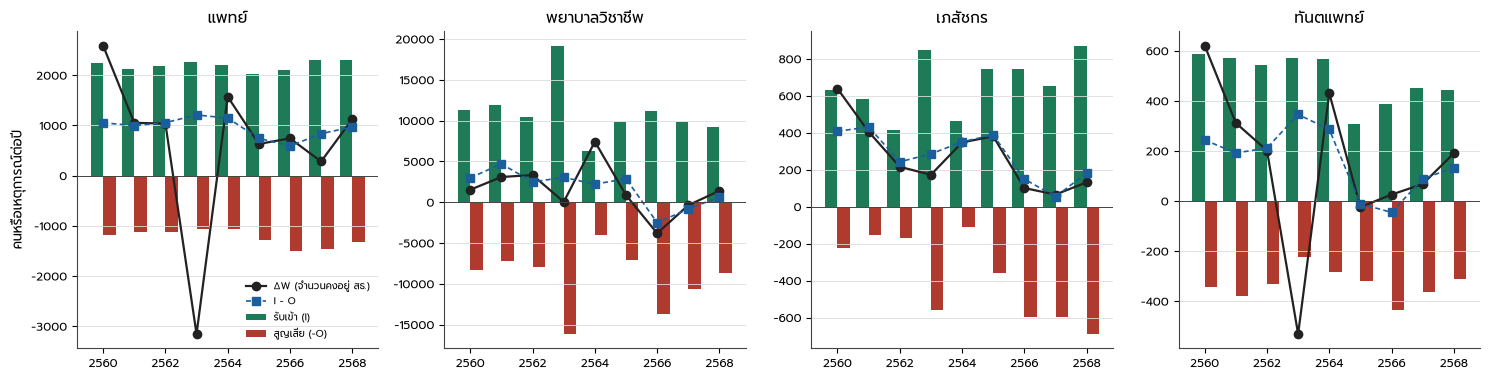

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.9))
for ax, c in zip(axes, CAD):
    z = natr[natr.cadre == c]
    ax.bar(z.year - 0.2, z.entry, width=0.4, color="#1e7b57", label="รับเข้า (I)")
    ax.bar(z.year + 0.2, -z.exit, width=0.4, color="#b03a2e", label="สูญเสีย (−O)")
    ax.plot(z.year, z.dW, color="#222", marker="o", lw=1.6, label="ΔW (จำนวนคงอยู่ สธ.)")
    ax.plot(z.year, z.net_flow, color="#1b5e9c", marker="s", lw=1.2, ls=(0, (3, 2)), label="I − O")
    ax.axhline(0, color="#444", lw=0.7); ax.set_title(c); R.be_ticks(ax, list(range(FY0, FY1 + 1)), 2); ax.grid(**R.GRID_KW)
axes[0].legend(frameon=False, fontsize=7); axes[0].set_ylabel("คนหรือเหตุการณ์ต่อปี")
fig.tight_layout()
S.figure("F44_STOCK_FLOW", fig, natr, "การรับเข้า การสูญเสีย การเปลี่ยนแปลงสุทธิที่บันทึก และการเปลี่ยนแปลงของจำนวนคงอยู่ (76 จังหวัด; ขอบเขตไม่ตรงกัน)", main=True)
plt.show()

## 4. อัตราการเติบโตที่ตรงช่วง และความเข้มของเหตุการณ์
$CAGR_{2559\rightarrow2568}=(W_{2568}/W_{2559})^{1/9}-1$ คู่กับ CAGR 2556–2568 ของ 4.1 (คนละคำถาม)
ความเข้ม = เหตุการณ์ต่อบุคลากรปีก่อน 100 คน (ตัวหารกว้างกว่าขอบเขตเหตุการณ์ จึงเป็นค่าประมาณ)
สัดส่วน ออก/รับเข้า เป็นแรงกดดันการทดแทน ไม่ใช่อัตราการคงอยู่ของรุ่น

In [8]:
inten = []
nat_w = W.groupby(["year", "cadre"]).W.sum().unstack()
nat_all = P.workforce_national("all_sectors").pivot(index="year", columns="cadre", values="headcount")
for c in CAD:
    f = rec[rec.cadre == c]
    ex_cat = EVL[(EVL.cadre == c) & (EVL.direction == "exit")].groupby("category").events.sum()
    en_cat = EVL[(EVL.cadre == c) & (EVL.direction == "entry")].groupby("category").events.sum()
    inten.append(dict(cadre=c, cagr_moph76_2016_2025=100 * M.cagr(nat_w[c][FY0 - 1], nat_w[c][FY1], FY1 - FY0 + 1),
                      cagr_moph76_2013_2025=100 * M.cagr(nat_w[c][2013], nat_w[c][FY1], FY1 - 2013),
                      cagr_allsectors_national_2013_2025=100 * M.cagr(nat_all[c][2013], nat_all[c][2025], 12),
                      entries_per100=100 * f.entry.sum() / f.W_prev.sum(), exits_per100=100 * f.exit.sum() / f.W_prev.sum(),
                      recruitment_per100=100 * en_cat.get("recruitment_hiring", 0) / f.W_prev.sum(),
                      resignations_per100=100 * ex_cat.get("resignation", 0) / f.W_prev.sum(),
                      retirements_per100=100 * ex_cat.get("retirement", 0) / f.W_prev.sum(),
                      transfer_in_per100=100 * en_cat.get("transfer_in", 0) / f.W_prev.sum(),
                      transfer_out_per100=100 * ex_cat.get("transfer_out", 0) / f.W_prev.sum(),
                      exit_entry_ratio=f.exit.sum() / f.entry.sum(), net_flow_per100=100 * (f.entry.sum() - f.exit.sum()) / f.W_prev.sum()))
INT = pd.DataFrame(inten)
S.table("T44_INTENSITY_NATIONAL", INT, "อัตราการเติบโตที่ตรงช่วงและความเข้มของเหตุการณ์ (ต่อบุคลากร สธ. ปีก่อน 100 คน, 76 จังหวัด)", main=True)
display(INT.round(2))
for r in INT.itertuples():
    for col in INT.columns[1:]:
        S.claim(f"c44_int_{EN[r.cadre]}_{col}", getattr(r, col), "{:.2f}", "", "T44_INTENSITY_NATIONAL")

# province intensities and typology (baseline density groups and the 4.3 priority list, never final growth)
pi = rec.groupby(["prov_code", "cadre"]).agg(entry=("entry", "sum"), exit=("exit", "sum"), W_prev_sum=("W_prev", "sum")).reset_index()
pi["entries_per100"] = 100 * pi.entry / pi.W_prev_sum
pi["exits_per100"] = 100 * pi.exit / pi.W_prev_sum
res_cat = EVL[EVL.category == "resignation"].groupby(["prov_code", "cadre"]).events.sum().rename("resignations")
pi = pi.merge(res_cat.reset_index(), on=["prov_code", "cadre"], how="left").fillna({"resignations": 0})
pi["resignations_per100"] = 100 * pi.resignations / pi.W_prev_sum
g = Wp.reset_index()
g["cagr_2016_2025"] = 100 * ((g[FY1] / g[FY0 - 1]) ** (1 / (FY1 - FY0 + 1)) - 1)
pop = P.registers().query("register=='civil_age'").pivot(index="prov_code", columns="year", values="population")
g["density_2016"] = 1e5 * g[FY0 - 1] / g.prov_code.map(pop[FY0 - 1])
pi = pi.merge(g[["prov_code", "cadre", "cagr_2016_2025", "density_2016"]], on=["prov_code", "cadre"])
pi["baseline_density_quartile"] = pi.groupby("cadre").density_2016.transform(lambda s: pd.qcut(s.rank(method="first"), 4, labels=["Q1 ต่ำสุด", "Q2", "Q3", "Q4 สูงสุด"]))
pri = PRI[(PRI.scope == "moph") & (PRI.denominator == "population")][["cadre", "prov_code", "priority"]]
pi = pi.merge(pri, on=["cadre", "prov_code"], how="left")
for c in CAD:
    m = pi.cadre == c
    pi.loc[m, "entry_high"] = pi.loc[m, "entries_per100"] >= pi.loc[m, "entries_per100"].median()
    pi.loc[m, "exit_high"] = pi.loc[m, "exits_per100"] >= pi.loc[m, "exits_per100"].median()
pi["typology"] = np.select([pi.entry_high.astype(bool) & pi.exit_high.astype(bool), pi.entry_high.astype(bool) & ~pi.exit_high.astype(bool),
                            ~pi.entry_high.astype(bool) & pi.exit_high.astype(bool)],
                           ["รับเข้าสูง-ออกสูง", "รับเข้าสูง-ออกต่ำ", "รับเข้าต่ำ-ออกสูง"], "รับเข้าต่ำ-ออกต่ำ")
pi["province"] = pi.prov_code.map(NAME)
S.table("T44_PROVINCE_INTENSITY", pi, "ความเข้มของการรับเข้า/ออกรายจังหวัด อัตราเติบโต 2559–2568 กลุ่มความหนาแน่นตั้งต้น และกลุ่มจังหวัดที่ควรให้ความสำคัญ (4.3)", main=True)
grp = pi.groupby(["cadre", "baseline_density_quartile"], observed=True).agg(
    provinces=("prov_code", "size"), entries_per100=("entry", "sum"), exits=("exit", "sum"), Wp=("W_prev_sum", "sum"), res=("resignations", "sum"),
    median_cagr=("cagr_2016_2025", "median")).reset_index()
grp["entries_per100"] = 100 * grp.entries_per100 / grp.Wp
grp["exits_per100"] = 100 * grp.exits / grp.Wp
grp["resignations_per100"] = 100 * grp.res / grp.Wp
S.table("T44_INTENSITY_BY_BASELINE_DENSITY", grp, "ความเข้มของเหตุการณ์ตามกลุ่มความหนาแน่นตั้งต้นปี 2559", main=True)
display(grp.round(2))
for r in grp.itertuples():
    q = r.baseline_density_quartile.split()[0]
    S.claim(f"c44_q_{EN[r.cadre]}_{q}_entries", r.entries_per100, "{:.1f}", "ต่อ 100")
    S.claim(f"c44_q_{EN[r.cadre]}_{q}_exits", r.exits_per100, "{:.1f}", "ต่อ 100")
    S.claim(f"c44_q_{EN[r.cadre]}_{q}_resign", r.resignations_per100, "{:.1f}", "ต่อ 100")
    S.claim(f"c44_q_{EN[r.cadre]}_{q}_cagr", r.median_cagr, "{:.2f}", "% ต่อปี")
pg = pi.groupby(["cadre", "priority"]).agg(entry=("entry", "sum"), exit=("exit", "sum"), Wp=("W_prev_sum", "sum"), res=("resignations", "sum"), cagr=("cagr_2016_2025", "median")).reset_index()
pg["entries_per100"], pg["exits_per100"], pg["resignations_per100"] = 100 * pg.entry / pg.Wp, 100 * pg.exit / pg.Wp, 100 * pg.res / pg.Wp
S.table("T44_INTENSITY_BY_PRIORITY", pg, "ความเข้มของเหตุการณ์ในกลุ่ม 19 จังหวัดที่ควรให้ความสำคัญ (ประชากร, สธ., 4.3) เทียบจังหวัดอื่น")
for r in pg.itertuples():
    t = "priority" if r.priority else "other"
    S.claim(f"c44_pri_{EN[r.cadre]}_{t}_entries", r.entries_per100, "{:.1f}", "ต่อ 100")
    S.claim(f"c44_pri_{EN[r.cadre]}_{t}_exits", r.exits_per100, "{:.1f}", "ต่อ 100")
    S.claim(f"c44_pri_{EN[r.cadre]}_{t}_resign", r.resignations_per100, "{:.1f}", "ต่อ 100")
typ = pi.groupby(["cadre", "typology"]).agg(provinces=("prov_code", "size"), median_cagr=("cagr_2016_2025", "median")).reset_index()
S.table("T44_TYPOLOGY", typ, "ประเภทจังหวัดตามความเข้มการรับเข้าและการออก (แบ่งที่มัธยฐาน) และอัตราเติบโตมัธยฐาน")
display(typ)
for r in typ.itertuples():
    S.claim(f"c44_typ_{EN[r.cadre]}_{r.typology}_n", r.provinces, "int", "จังหวัด")
    S.claim(f"c44_typ_{EN[r.cadre]}_{r.typology}_cagr", r.median_cagr, "{:.2f}", "% ต่อปี")
neg = pi.merge(rec.groupby(["prov_code", "cadre"]).agg(net=("net_flow", "sum"), dW=("dW", "sum")).reset_index(), on=["prov_code", "cadre"])
fall = neg[(neg.dW < 0) & (neg.net > 0)]
S.table("T44_FALLING_STOCK_POSITIVE_FLOW", fall, "จังหวัดที่จำนวนคงอยู่ลดลงทั้งที่การรับเข้าสุทธิที่บันทึกเป็นบวก (ข้อจำกัดของการกระทบยอด)")
for c in CAD:
    S.claim(f"c44_fall_pos_{EN[c]}", int((fall.cadre == c).sum()), "int", "จังหวัด")

,cadre,cagr_moph76_2016_2025,cagr_moph76_2013_2025,cagr_allsectors_national_2013_2025,entries_per100,exits_per100,recruitment_per100,resignations_per100,retirements_per100,transfer_in_per100,transfer_out_per100,exit_entry_ratio,net_flow_per100
0,แพทย์,3.39,3.52,4.60,10.99,6.20,10.53,5.34,0.60,0.03,0.20,0.56,4.79
1,พยาบาลวิชาชีพ,1.34,2.02,3.27,9.57,8.06,9.44,6.13,1.11,0.10,0.75,0.84,1.51
2,เภสัชกร,2.97,3.52,3.61,6.89,4.00,6.72,3.57,0.26,0.13,0.10,0.58,2.89
3,ทันตแพทย์,2.66,2.49,1.29,8.66,5.84,8.51,5.17,0.32,0.08,0.31,0.67,2.83


,cadre,baseline_density_quartile,provinces,entries_per100,exits,Wp,res,median_cagr,exits_per100,resignations_per100
0,ทันตแพทย์,Q1 ต่ำสุด,19,12.55,1068.0,14742.0,970.0,3.97,7.24,6.58
1,ทันตแพทย์,Q2,19,8.36,840.0,14580.0,751.0,2.89,5.76,5.15
2,ทันตแพทย์,Q3,19,5.90,654.0,12517.0,549.0,2.54,5.22,4.39
3,ทันตแพทย์,Q4 สูงสุด,19,6.70,425.0,9346.0,375.0,1.00,4.55,4.01
4,พยาบาลวิชาชีพ,Q1 ต่ำสุด,19,11.13,28946.0,326899.0,23304.0,2.86,8.85,7.13
5,พยาบาลวิชาชีพ,Q2,19,10.03,21241.0,253156.0,16145.0,1.40,8.39,6.38
6,พยาบาลวิชาชีพ,Q3,19,9.49,21116.0,265926.0,16054.0,0.70,7.94,6.04
7,พยาบาลวิชาชีพ,Q4 สูงสุด,19,6.43,12403.0,192430.0,8135.0,-0.96,6.45,4.23
8,เภสัชกร,Q1 ต่ำสุด,19,8.08,1099.0,25228.0,1010.0,3.55,4.36,4.00
9,เภสัชกร,Q2,19,7.10,1023.0,23887.0,914.0,3.06,4.28,3.83


,cadre,typology,provinces,median_cagr
0,ทันตแพทย์,รับเข้าต่ำ-ออกต่ำ,27,2.169774
1,ทันตแพทย์,รับเข้าต่ำ-ออกสูง,11,2.226388
2,ทันตแพทย์,รับเข้าสูง-ออกต่ำ,11,3.145266
3,ทันตแพทย์,รับเข้าสูง-ออกสูง,27,3.215471
4,พยาบาลวิชาชีพ,รับเข้าต่ำ-ออกต่ำ,31,0.190662
5,พยาบาลวิชาชีพ,รับเข้าต่ำ-ออกสูง,7,0.619737
6,พยาบาลวิชาชีพ,รับเข้าสูง-ออกต่ำ,7,3.186885
7,พยาบาลวิชาชีพ,รับเข้าสูง-ออกสูง,31,1.609675
8,เภสัชกร,รับเข้าต่ำ-ออกต่ำ,33,2.951640
9,เภสัชกร,รับเข้าต่ำ-ออกสูง,5,2.510365


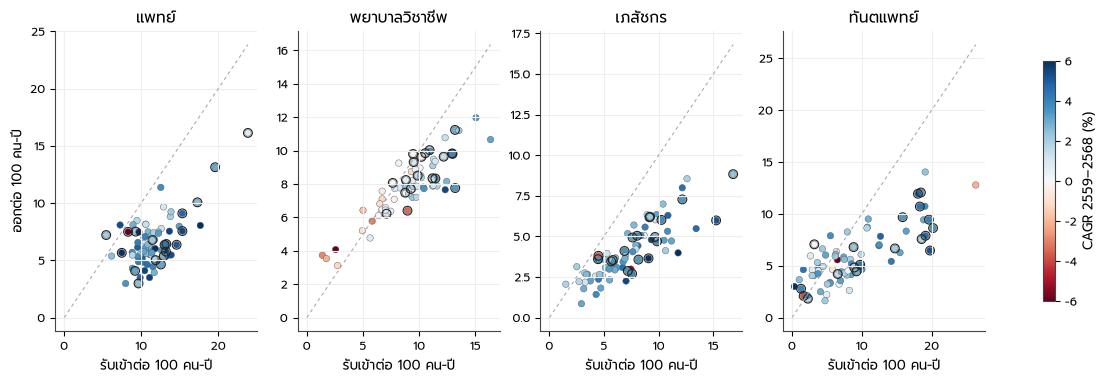

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.9))
for ax, c in zip(axes, CAD):
    z = pi[pi.cadre == c]
    sc = ax.scatter(z.entries_per100, z.exits_per100, c=z.cagr_2016_2025, cmap="RdBu", vmin=-6, vmax=6, s=22, edgecolor="#555", lw=0.3)
    ax.plot([0, z[["entries_per100", "exits_per100"]].max().max()], [0, z[["entries_per100", "exits_per100"]].max().max()], color="#aaa", lw=0.8, ls=(0, (3, 3)))
    for _, r in z[z.priority == True].iterrows():
        ax.scatter(r.entries_per100, r.exits_per100, s=40, facecolor="none", edgecolor="#222", lw=0.8)
    ax.set_title(c); ax.set_xlabel("รับเข้าต่อ 100 คน-ปี"); ax.grid(color="#eee")
axes[0].set_ylabel("ออกต่อ 100 คน-ปี")
fig.colorbar(sc, ax=axes, shrink=0.8, label="CAGR 2559–2568 (%)")
S.figure("F44_PROVINCE_FLOWS", fig, pi, "ความเข้มของการรับเข้าและการออกรายจังหวัด ปีงบ 2560–2568 (สี = อัตราเติบโตของจำนวนคงอยู่; วงกลมดำ = กลุ่มที่ควรให้ความสำคัญใน 4.3)", main=True)
plt.show()

## 5. ภาระงานปีก่อน บริบทเศรษฐกิจ กับการรับเข้าและการออก (PPML)
กำหนดแบบจำลองหลักล่วงหน้า: $\log E[F_{pct}]=\log W_{pc,t-1}+\alpha_{pc}+\delta_t+\beta'\log L_{pc,t-1}+\gamma\log GPP_{p,t-1}$
แยกวิชาชีพ; province และ year FE; cluster จังหวัด; จังหวัดที่เหตุการณ์เป็นศูนย์ทุกปีถูกตัด (ไม่มีข้อมูลสำหรับ FE)
ภาระงาน: แพทย์ = log ครั้ง OP และ log วันนอนต่อแพทย์; พยาบาล = log วันนอนต่อพยาบาล; เภสัชกร/ทันตแพทย์ = ไม่มีข้อมูลกิจกรรมที่ยาวพอสำหรับ lag (มีเพียง 2565–2568)
ความไว: AdjRW ต่อบุคลากรบนตัวอย่างเดียวกันช่วงสั้น, ตัด COVID (ปีงบ 2563–2565), offset + ตัวแปร log stock อิสระ (elasticity รวม = 1+β), ตัดจังหวัดที่มีอิทธิพลสูงสุด

In [10]:
pan, _ = P.province_panel()
svc = pan[["prov_code", "year", "moph_op_visits", "moph_ip_days", "sum_adjrw", "log_gpp_lag1"]]
ev_cat = EVL.groupby(["fiscal_year", "prov_code", "cadre", "direction", "category"]).events.sum().unstack(["direction", "category"]).fillna(0)
ev_cat.columns = [f"{a}__{b}" for a, b in ev_cat.columns]
ev_cat = ev_cat.reset_index().rename(columns={"fiscal_year": "year"})
ev_cat["entry__all"] = ev_cat.filter(like="entry__").sum(axis=1)
ev_cat["exit__all"] = ev_cat[[c for c in ev_cat.columns if c.startswith("exit__") and c != "exit__all"]].sum(axis=1)
OUTCOMES = {"entry__all": "การรับเข้าทั้งหมด", "entry__recruitment_hiring": "บรรจุ/จ้าง", "exit__resignation": "ลาออก", "exit__all": "การออกทั้งหมด"}
# lagged workload: t-1 service (report / fiscal year) per t-1 MOPH staff, exact-year join
lagged = W.merge(svc, on=["prov_code", "year"], how="left")
lagged["log_op_per_staff"] = np.log(lagged.moph_op_visits / lagged.W)
lagged["log_ipd_per_staff"] = np.log(lagged.moph_ip_days / lagged.W)
lagged["log_adjrw_per_staff"] = np.log(lagged.sum_adjrw / lagged.W)
lagged["log_stock"] = np.log(lagged.W)
lag = lagged.assign(year=lagged.year + 1)[["prov_code", "cadre", "year", "W", "log_op_per_staff", "log_ipd_per_staff", "log_adjrw_per_staff", "log_stock"]].rename(
    columns={"W": "W_prev", "log_op_per_staff": "L_op", "log_ipd_per_staff": "L_ipd", "log_adjrw_per_staff": "L_adjrw", "log_stock": "log_W_prev"})
gdp = pan[["prov_code", "year", "log_gpp_lag1"]]          # GPP of t-1 relative to event year t
D = ev_cat.merge(lag, on=["prov_code", "cadre", "year"], how="left", validate="one_to_one").merge(gdp, on=["prov_code", "year"], how="left")
assert D.W_prev.notna().all()
WL = {"แพทย์": ["L_op", "L_ipd"], "พยาบาลวิชาชีพ": ["L_ipd"]}
ALT = {"แพทย์": ["L_op", "L_adjrw"], "พยาบาลวิชาชีพ": ["L_adjrw"]}


def fit(df, y, xs, variant, extra_stock=False):
    z = df.dropna(subset=xs + ["log_gpp_lag1", "W_prev"]).copy()
    allzero = z.groupby("prov_code")[y].transform("sum") == 0
    dropped = int(z[allzero].prov_code.nunique())
    z = z[~allzero]
    cols = xs + ["log_gpp_lag1"] + (["log_W_prev"] if extra_stock else [])
    r = MD.ppml(z, y, cols, "W_prev", ["prov_code", "year"], "prov_code")
    t = r["table"]
    t = t[t.term.isin(xs + (["log_W_prev"] if extra_stock else []))].copy()
    t["variant"], t["outcome"], t["n"], t["provinces"], t["dropped_all_zero_provinces"] = variant, y, r["n"], r["clusters"], dropped
    t["years"] = f"{z.year.min()}-{z.year.max()}"
    t["converged"], t["pearson_dispersion"], t["events"] = r["converged"], r["pearson_dispersion"], z[y].sum()
    return t, r


res, infl = [], []
for c, xs in WL.items():
    d = D[D.cadre == c]
    for y in OUTCOMES:
        t, r = fit(d, y, xs, "primary"); res.append(t.assign(cadre=c))
        t, _ = fit(d, y, xs, "offset_plus_free_log_stock", extra_stock=True); res.append(t.assign(cadre=c))
        t, _ = fit(d[~d.year.isin([2020, 2021, 2022])], y, xs, "exclude_covid_fy2020_2022"); res.append(t.assign(cadre=c))
        short = d.dropna(subset=ALT[c])
        t, _ = fit(short, y, xs, "primary_on_adjrw_sample"); res.append(t.assign(cadre=c))
        t, _ = fit(short, y, ALT[c], "adjrw_workload_same_sample"); res.append(t.assign(cadre=c))
        # influence: drop the province whose removal moves the first workload coefficient most
        base = r["table"].set_index("term").coef[xs[0]]
        shifts = {}
        for p in d.prov_code.unique():
            try:
                tt, _ = fit(d[d.prov_code != p], y, xs, "loo")
                shifts[p] = abs(tt.set_index("term").coef[xs[0]] - base)
            except Exception:
                continue
        pmax = max(shifts, key=shifts.get)
        t, _ = fit(d[d.prov_code != pmax], y, xs, f"drop_most_influential_{NAME[pmax]}"); res.append(t.assign(cadre=c))
        infl.append(dict(cadre=c, outcome=y, province=NAME[pmax], coefficient_shift=shifts[pmax]))
ASSOC = pd.concat(res, ignore_index=True)
for col in ["coef", "lo95", "hi95"]:
    ASSOC[f"pct_for_10pct_{col}"] = M.pct_for_10pct(ASSOC[col])
ASSOC["direction"] = np.where(ASSOC.lo95 > 0, "positive", np.where(ASSOC.hi95 < 0, "negative", "inconclusive"))
ASSOC.loc[ASSOC.term == "log_W_prev", "effective_stock_elasticity"] = 1 + ASSOC.loc[ASSOC.term == "log_W_prev", "coef"]
S.table("T44_WORKLOAD_ASSOCIATIONS", ASSOC, "ความสัมพันธ์ระหว่างภาระงานปีก่อนกับเหตุการณ์ (PPML, province+year FE, cluster จังหวัด) — ความสัมพันธ์ ไม่ใช่ผลเชิงเหตุผล", main=True)
S.table("T44_INFLUENCE", pd.DataFrame(infl), "จังหวัดที่มีอิทธิพลสูงสุดต่อสัมประสิทธิ์ภาระงาน")
prim = ASSOC[ASSOC.variant == "primary"]
display(prim[["cadre", "outcome", "term", "coef", "lo95", "hi95", "pct_for_10pct_coef", "pct_for_10pct_lo95", "pct_for_10pct_hi95", "n", "years", "direction"]].round(3))
display(ASSOC[ASSOC.variant != "primary"][["cadre", "outcome", "variant", "term", "coef", "lo95", "hi95", "direction"]].round(3))
for r in ASSOC.itertuples():
    tag = f"c44_wl_{EN[r.cadre]}_{r.outcome}_{r.term}_{r.variant.split('_')[0] if r.variant.startswith('drop') else r.variant}"
    S.claim(tag, r.coef, "{:.3f}", "", "T44_WORKLOAD_ASSOCIATIONS")
    S.claim(tag + "_p10", r.pct_for_10pct_coef, "{:.1f}", "%")
    S.claim(tag + "_p10lo", r.pct_for_10pct_lo95, "{:.1f}", "%")
    S.claim(tag + "_p10hi", r.pct_for_10pct_hi95, "{:.1f}", "%")
    S.text_claim(tag + "_dir", r.direction)
dirs = prim.direction.value_counts()
S.claim("c44_wl_primary_n_terms", len(prim), "int", "")
S.claim("c44_wl_primary_n_inconclusive", int(dirs.get("inconclusive", 0)), "int", "")
S.claim("c44_wl_primary_n_positive", int(dirs.get("positive", 0)), "int", "")
S.claim("c44_wl_primary_n_negative", int(dirs.get("negative", 0)), "int", "")
S.claim("c44_wl_n_obs", prim.n.max(), "int", "จังหวัด-ปี")
S.text_claim("c44_wl_years", prim.years.iloc[0])

,cadre,outcome,term,coef,lo95,hi95,pct_for_10pct_coef,pct_for_10pct_lo95,pct_for_10pct_hi95,n,years,direction
0,แพทย์,entry__all,L_op,0.381,0.160,0.601,3.697,1.541,5.898,684,2017-2025,positive
1,แพทย์,entry__all,L_ipd,0.102,-0.123,0.326,0.972,-1.165,3.156,684,2017-2025,inconclusive
13,แพทย์,entry__recruitment_hiring,L_op,0.390,0.164,0.617,3.792,1.576,6.056,684,2017-2025,positive
14,แพทย์,entry__recruitment_hiring,L_ipd,0.107,-0.114,0.327,1.022,-1.082,3.171,684,2017-2025,inconclusive
26,แพทย์,exit__resignation,L_op,0.104,-0.094,0.303,0.999,-0.894,2.929,684,2017-2025,inconclusive
27,แพทย์,exit__resignation,L_ipd,0.008,-0.199,0.216,0.079,-1.878,2.075,684,2017-2025,inconclusive
39,แพทย์,exit__all,L_op,0.112,-0.095,0.318,1.070,-0.898,3.076,684,2017-2025,inconclusive
40,แพทย์,exit__all,L_ipd,-0.042,-0.238,0.154,-0.399,-2.239,1.476,684,2017-2025,inconclusive
52,พยาบาลวิชาชีพ,entry__all,L_ipd,0.483,0.227,0.738,4.709,2.191,7.289,684,2017-2025,positive
59,พยาบาลวิชาชีพ,entry__recruitment_hiring,L_ipd,0.478,0.221,0.736,4.666,2.126,7.269,684,2017-2025,positive


,cadre,outcome,variant,term,coef,lo95,hi95,direction
2,แพทย์,entry__all,offset_plus_free_log_stock,L_op,0.173,-0.018,0.364,inconclusive
3,แพทย์,entry__all,offset_plus_free_log_stock,L_ipd,-0.101,-0.288,0.086,inconclusive
4,แพทย์,entry__all,offset_plus_free_log_stock,log_W_prev,-1.371,-1.799,-0.943,negative
5,แพทย์,entry__all,exclude_covid_fy2020_2022,L_op,0.505,0.220,0.790,positive
6,แพทย์,entry__all,exclude_covid_fy2020_2022,L_ipd,0.185,-0.088,0.459,inconclusive
...,...,...,...,...,...,...,...,...
75,พยาบาลวิชาชีพ,exit__all,offset_plus_free_log_stock,log_W_prev,-1.469,-1.941,-0.998,negative
76,พยาบาลวิชาชีพ,exit__all,exclude_covid_fy2020_2022,L_ipd,0.279,-0.051,0.610,inconclusive
77,พยาบาลวิชาชีพ,exit__all,primary_on_adjrw_sample,L_ipd,-0.008,-0.246,0.231,inconclusive
78,พยาบาลวิชาชีพ,exit__all,adjrw_workload_same_sample,L_adjrw,-0.270,-0.614,0.074,inconclusive


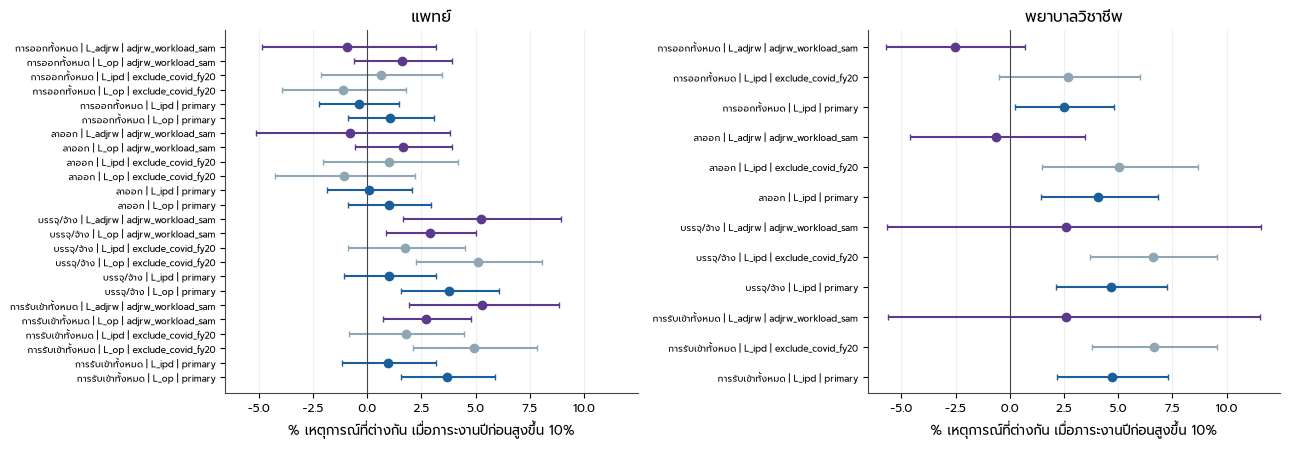

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharex=True)
for ax, c in zip(axes, WL):
    z = ASSOC[(ASSOC.cadre == c) & ASSOC.variant.isin(["primary", "exclude_covid_fy2020_2022", "adjrw_workload_same_sample"]) & (ASSOC.term != "log_W_prev")].reset_index(drop=True)
    for i, r in z.iterrows():
        col = {"primary": "#1b5e9c", "exclude_covid_fy2020_2022": "#8fa6b4", "adjrw_workload_same_sample": "#5b3a8e"}[r.variant]
        ax.errorbar(r.pct_for_10pct_coef, i, xerr=[[r.pct_for_10pct_coef - r.pct_for_10pct_lo95], [r.pct_for_10pct_hi95 - r.pct_for_10pct_coef]], fmt="o", color=col, capsize=2)
    ax.axvline(0, color="#444", lw=0.8)
    ax.set_yticks(range(len(z))); ax.set_yticklabels([f"{OUTCOMES[r.outcome]} | {r.term} | {r.variant[:18]}" for r in z.itertuples()], fontsize=6.5)
    ax.set_title(c); ax.set_xlabel("% เหตุการณ์ที่ต่างกัน เมื่อภาระงานปีก่อนสูงขึ้น 10%"); ax.grid(axis="x", color="#eee")
fig.tight_layout()
S.figure("F44_WORKLOAD_ASSOCIATIONS", fig, ASSOC, "ความสัมพันธ์ระหว่างภาระงานปีก่อนกับการรับเข้าและการออก (PPML; ช่วง 95%)", main=True)
plt.show()

## 6. ตารางพารามิเตอร์สำหรับแบบจำลองวางแผนในอนาคต

In [12]:
par = []
for r in INT.itertuples():
    pv = pi[pi.cadre == r.cadre]
    for q, val, spread, ev_type, use in [
        ("อัตรารับเข้าทั้งหมดต่อบุคลากรปีก่อน 100 คน", r.entries_per100, pv.entries_per100.quantile([.1, .9]).round(1).tolist(), "เหตุการณ์ที่บันทึก; ตัวหารกว้างกว่าขอบเขต", "ฉากทัศน์ฐาน (ระบุข้อจำกัดขอบเขต)"),
        ("อัตราออกทั้งหมดต่อบุคลากรปีก่อน 100 คน", r.exits_per100, pv.exits_per100.quantile([.1, .9]).round(1).tolist(), "เหตุการณ์ที่บันทึก", "ฉากทัศน์ฐาน"),
        ("อัตราลาออกต่อบุคลากรปีก่อน 100 คน", r.resignations_per100, pv.resignations_per100.quantile([.1, .9]).round(1).tolist(), "เหตุการณ์ที่บันทึก", "ฉากทัศน์ฐาน; ไม่ใช่ความน่าจะเป็นรายบุคคล"),
        ("สัดส่วน ออก/รับเข้า", r.exit_entry_ratio, [], "เชิงพรรณนา", "แรงกดดันการทดแทน ไม่ใช่อัตราคงอยู่ของรุ่น"),
        ("CAGR จำนวนคงอยู่ สธ. 2559–2568 (76 จังหวัด)", r.cagr_moph76_2016_2025, [], "จำนวนคงอยู่ (ขอบเขตกว้างกว่า)", "ตรวจความสอดคล้องของฉากทัศน์")]:
        par.append(dict(cadre=r.cadre, quantity=q, definition=q, scope="สป.สธ. เหตุการณ์ / สธ. จำนวนคงอยู่ 76 จังหวัด", period=f"ปีงบ {C.be(FY0)}–{C.be(FY1)}",
                        estimate=val, province_p10_p90=spread, evidence_type=ev_type, permitted_use=use,
                        missing_inputs="ข้อมูลรายบุคคลที่เชื่อมโยงได้ (รุ่น อายุงาน ปลายทางการโอนย้าย) และจำนวนคงอยู่ขอบเขต สป.สธ."))
for r in prim.itertuples():
    par.append(dict(cadre=r.cadre, quantity=f"ความสัมพันธ์ {r.term} → {OUTCOMES[r.outcome]}", definition="% เหตุการณ์ต่างกันต่อภาระงานปีก่อนสูงขึ้น 10%",
                    scope="76 จังหวัด", period=r.years, estimate=r.pct_for_10pct_coef, province_p10_p90=[round(r.pct_for_10pct_lo95, 1), round(r.pct_for_10pct_hi95, 1)],
                    evidence_type="ความสัมพันธ์เชิงสังเกต (ช่วง 95%)", permitted_use="ไม่ใช้เป็นการตอบสนองเชิงเหตุผลต่อการลดภาระงาน",
                    missing_inputs="การเปลี่ยนแปลงภาระงานที่เป็นอิสระจากปัจจัยอื่น (เช่น นโยบาย) และภาระงานรายบุคคล"))
PAR = pd.DataFrame(par)
S.table("T44_FUTURE_MODEL_PARAMETERS", PAR, "สถานะพารามิเตอร์สำหรับแบบจำลองวางแผนกำลังคนในอนาคต", main=True)
display(PAR.head(12))

,cadre,quantity,definition,scope,period,estimate,province_p10_p90,evidence_type,permitted_use,missing_inputs
0,แพทย์,อัตรารับเข้าทั้งหมดต่อบุคลากรปีก่อน 100 คน,อัตรารับเข้าทั้งหมดต่อบุคลากรปีก่อน 100 คน,สป.สธ. เหตุการณ์ / สธ. จำนวนคงอยู่ 76 จังหวัด,ปีงบ 2560–2568,10.986651,"[8.9, 14.2]",เหตุการณ์ที่บันทึก; ตัวหารกว้างกว่าขอบเขต,ฉากทัศน์ฐาน (ระบุข้อจำกัดขอบเขต),ข้อมูลรายบุคคลที่เชื่อมโยงได้ (รุ่น อายุงาน ปล...
1,แพทย์,อัตราออกทั้งหมดต่อบุคลากรปีก่อน 100 คน,อัตราออกทั้งหมดต่อบุคลากรปีก่อน 100 คน,สป.สธ. เหตุการณ์ / สธ. จำนวนคงอยู่ 76 จังหวัด,ปีงบ 2560–2568,6.196685,"[4.2, 8.7]",เหตุการณ์ที่บันทึก,ฉากทัศน์ฐาน,ข้อมูลรายบุคคลที่เชื่อมโยงได้ (รุ่น อายุงาน ปล...
2,แพทย์,อัตราลาออกต่อบุคลากรปีก่อน 100 คน,อัตราลาออกต่อบุคลากรปีก่อน 100 คน,สป.สธ. เหตุการณ์ / สธ. จำนวนคงอยู่ 76 จังหวัด,ปีงบ 2560–2568,5.335292,"[3.3, 7.7]",เหตุการณ์ที่บันทึก,ฉากทัศน์ฐาน; ไม่ใช่ความน่าจะเป็นรายบุคคล,ข้อมูลรายบุคคลที่เชื่อมโยงได้ (รุ่น อายุงาน ปล...
3,แพทย์,สัดส่วน ออก/รับเข้า,สัดส่วน ออก/รับเข้า,สป.สธ. เหตุการณ์ / สธ. จำนวนคงอยู่ 76 จังหวัด,ปีงบ 2560–2568,0.564019,[],เชิงพรรณนา,แรงกดดันการทดแทน ไม่ใช่อัตราคงอยู่ของรุ่น,ข้อมูลรายบุคคลที่เชื่อมโยงได้ (รุ่น อายุงาน ปล...
4,แพทย์,CAGR จำนวนคงอยู่ สธ. 2559–2568 (76 จังหวัด),CAGR จำนวนคงอยู่ สธ. 2559–2568 (76 จังหวัด),สป.สธ. เหตุการณ์ / สธ. จำนวนคงอยู่ 76 จังหวัด,ปีงบ 2560–2568,3.393929,[],จำนวนคงอยู่ (ขอบเขตกว้างกว่า),ตรวจความสอดคล้องของฉากทัศน์,ข้อมูลรายบุคคลที่เชื่อมโยงได้ (รุ่น อายุงาน ปล...
5,พยาบาลวิชาชีพ,อัตรารับเข้าทั้งหมดต่อบุคลากรปีก่อน 100 คน,อัตรารับเข้าทั้งหมดต่อบุคลากรปีก่อน 100 คน,สป.สธ. เหตุการณ์ / สธ. จำนวนคงอยู่ 76 จังหวัด,ปีงบ 2560–2568,9.568947,"[6.1, 12.4]",เหตุการณ์ที่บันทึก; ตัวหารกว้างกว่าขอบเขต,ฉากทัศน์ฐาน (ระบุข้อจำกัดขอบเขต),ข้อมูลรายบุคคลที่เชื่อมโยงได้ (รุ่น อายุงาน ปล...
6,พยาบาลวิชาชีพ,อัตราออกทั้งหมดต่อบุคลากรปีก่อน 100 คน,อัตราออกทั้งหมดต่อบุคลากรปีก่อน 100 คน,สป.สธ. เหตุการณ์ / สธ. จำนวนคงอยู่ 76 จังหวัด,ปีงบ 2560–2568,8.060970,"[6.2, 9.8]",เหตุการณ์ที่บันทึก,ฉากทัศน์ฐาน,ข้อมูลรายบุคคลที่เชื่อมโยงได้ (รุ่น อายุงาน ปล...
7,พยาบาลวิชาชีพ,อัตราลาออกต่อบุคลากรปีก่อน 100 คน,อัตราลาออกต่อบุคลากรปีก่อน 100 คน,สป.สธ. เหตุการณ์ / สธ. จำนวนคงอยู่ 76 จังหวัด,ปีงบ 2560–2568,6.128402,"[4.1, 7.8]",เหตุการณ์ที่บันทึก,ฉากทัศน์ฐาน; ไม่ใช่ความน่าจะเป็นรายบุคคล,ข้อมูลรายบุคคลที่เชื่อมโยงได้ (รุ่น อายุงาน ปล...
8,พยาบาลวิชาชีพ,สัดส่วน ออก/รับเข้า,สัดส่วน ออก/รับเข้า,สป.สธ. เหตุการณ์ / สธ. จำนวนคงอยู่ 76 จังหวัด,ปีงบ 2560–2568,0.842409,[],เชิงพรรณนา,แรงกดดันการทดแทน ไม่ใช่อัตราคงอยู่ของรุ่น,ข้อมูลรายบุคคลที่เชื่อมโยงได้ (รุ่น อายุงาน ปล...
9,พยาบาลวิชาชีพ,CAGR จำนวนคงอยู่ สธ. 2559–2568 (76 จังหวัด),CAGR จำนวนคงอยู่ สธ. 2559–2568 (76 จังหวัด),สป.สธ. เหตุการณ์ / สธ. จำนวนคงอยู่ 76 จังหวัด,ปีงบ 2560–2568,1.336813,[],จำนวนคงอยู่ (ขอบเขตกว้างกว่า),ตรวจความสอดคล้องของฉากทัศน์,ข้อมูลรายบุคคลที่เชื่อมโยงได้ (รุ่น อายุงาน ปล...


In [13]:
manifest = S.finalize()
print({k: manifest[k] for k in ["n_tables", "n_figures", "n_claims", "seconds"]})

{'n_tables': 32, 'n_figures': 3, 'n_claims': 703, 'seconds': 26.3}
